# Map flux
## Make the same maps as the one presented in https://arxiv.org/pdf/2104.06855.pdf

### Import modules

In [82]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap
import pandas as pd
from scipy.interpolate import interp1d

### User parameters

In [83]:
incl = 48 * np.pi / 180.0
Nx = 32
f_Ny = 0.15 # Nyquist frequency (< 0.6)
#co = sqrt(8.d0*log(2.d0))       ! difference between sigma and theta!, theta = sigma*co

### Define some constants

In [84]:
M_BH = 5.5e7 #             !Black hole mass [Msun]
R_g = 1.477e5*M_BH

h = 6.6260755e-27
k_B = 1.380658e-16
m_e = 9.10938e-28
c = 2.99792458e10
e = 4.8032068e-10
kpc = 3.0856e21  #Kpc a cm
distance = 3.8e3  #Distancia al objeto en kpc
convert = 206265e3/(distance*kpc) # image to angular size (mas)
# flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

### Define some useful functions

In [85]:
def safe_log(x):
    return np.where(x > 0, np.log(x), -300)

#### Obtenemos la emisividad y absorcion para cada z

In [86]:
def get_j_alpha(nu, delta, filename='./../Code/Em_Abs.dat'):
    # Read the data from the file
    data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
    
    # Find the energy associated with the given frequency nu
    energy_nu = h * nu * 1e9  # Convert frequency to energy
    
    # Filter the data for each z_value
    filtered_data = []
    for z in data["z_value"].unique():
        z_data = data[data["z_value"] == z]
        closest_index = (np.abs(z_data["energy"] - energy_nu/delta[z-1])).idxmin()
        filtered_data.append(z_data.loc[closest_index, ["energy", "emisivity", "absorption"]])

    # Combine the filtered data into a DataFrame
    filtered_data = pd.DataFrame(filtered_data)
    return filtered_data['emisivity'], filtered_data['absorption']

#### Obtenemos los valores de las cantidades que varian con z

In [87]:
def get_z_rz(filename='./../Code/quant_FF.dat',filename2='./../Code/quant_FF_norm.dat'):
    """
    Load and return specific columns from the given file.

    Parameters:
        filename (str): Path to the file containing the data.

    Returns:
        tuple: Arrays of z, B, r_out, r_in, and delta_obs values.
    """
    return np.loadtxt(filename, usecols=(0, 1, 2, 3, 5), unpack=True)

#### Funcion que calcula l(x,z)

In [88]:
def crossed_length(x, R_in, R_out):
        if abs(x) < abs(R_out) and abs(x) > abs(R_in):
                l = 2.0 * np.sqrt(R_out**2 - x**2)
        elif abs(x) <= abs(R_in):
                l = 2.0 * (np.sqrt(R_out**2 - x**2) - np.sqrt(abs(R_in**2 - x**2)))
        else:
                l = 0.0
        return l

#### Temperatura de Brillo

In [89]:
def Omega_beam(theta1, theta2):
    '''Beam solid angle in terms of the theta_HPBW (theta1 x theta2)
    Use the equation here: https://science.nrao.edu/facilities/vla/proposing/TBconv'''
    return np.pi * theta1 * theta2 / (4 * np.log(2))

def brightness_temperature(I, nu_hz):
    """
    Calculate the brightness temperature for a given intensity and frequency.

    Parameters:
    I (float or numpy.ndarray): Specific intensity [erg/s/cm^2/Hz].
    nu (float): Frequency [Hz].

    Returns:
    float or numpy.ndarray: Brightness temperature [K].
    """
    nu_hz *= 1e9 # Convert GHz to Hz
    

    return I/Omega_beam(0.0168*1e-3,0.0259*1e-3)#(c**2 * I) / (2 * k_B * nu_hz**2*Omega_beam(np.deg2rad(23 * 1e-3 / 3600),np.deg2rad(45 * 1e-3 / 3600))) #[K]

#### Calculamos el valor de la intensidad I(x,z)

In [90]:
#Esta interpola las funciones de z
def Intensity_import_interp(x_value, nu, z_value):
    '''
    Function that returns the intensity for a given frequency at a given range of z, determined by the length of the input array.
    The function uses the values of absoption and emissivity imported from the function get_j_alpha that are closest to the specified energy
    (given by nu) to calculate the intensity based on the input parameters.
    
    This function interpolates for any given value of z'''

    # Retrieve data
    if not hasattr(Intensity_import_interp, "_cached_data"):
        z, B, r_out, r_in, delta_obs = get_z_rz()
        delta_obs = np.sqrt(delta_obs)
        j, alpha = get_j_alpha(nu, delta_obs)
        Intensity_import_interp._cached_data = (z, B, r_out, r_in, delta_obs, j, alpha)
    else:
        z, B, r_out, r_in, delta_obs, j, alpha = Intensity_import_interp._cached_data
    j=j.to_numpy()
    alpha=alpha.to_numpy()
    # Precompute constants

    # Interpolations
    I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]
    term_exp_values = [alpha[idx] / delta_obs[idx] for idx in range(len(z))]
    # Remove NaN values from I_z_values and term_exp_values
    valid_indices = ~np.isnan(I_z_values) & ~np.isnan(term_exp_values)
    I_z_values = np.array(I_z_values)[valid_indices]
    term_exp_values = np.array(term_exp_values)[valid_indices]
    z2 = np.array(z)[valid_indices]

    I_z = interp1d(safe_log(z2), safe_log(I_z_values), bounds_error=False, fill_value='extrapolate')
    term_exp = interp1d(safe_log(z2), safe_log(term_exp_values), bounds_error=False, fill_value='extrapolate')
    r_out_interp = interp1d(safe_log(z), safe_log(r_out), bounds_error=False, fill_value='extrapolate')
    r_in_interp = interp1d(safe_log(z), safe_log(r_in), bounds_error=False, fill_value='extrapolate')

    # Compute intensity
    intensity_result = np.zeros(len(x_value))
    r_avg=0.5*(np.exp(r_out_interp(safe_log(z_value)))+np.exp(r_in_interp(safe_log(z_value))))
    tau_avg=crossed_length(r_avg, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
    for j, x in enumerate(x_value):
        tau = crossed_length(x, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
        intensity_result[j] = np.exp(I_z(safe_log(z_value))) * (-np.expm1(-tau)) #(1+tau)# opt thin #[erg/cm^2/s/erg/sr]
    

    return intensity_result*h, tau_avg #[erg/cm^2/s/Hz/sr]



In [91]:
z, _, r_out, _, _ = get_z_rz()
z = np.linspace(z.min(), z.max(), 200)
x = np.linspace(-r_out.max(), r_out.max(), 200)
#x = np.linspace(-r_out.max(), r_out.max(), 200)
# Create a meshgrid for plotting
X_m, Z_m = np.meshgrid(x, z)
I = np.zeros((len(z), len(x)))
tau_avg= np.zeros(len(z))
for i, z_value in enumerate(z):
    I[i], tau_avg[i]=Intensity_import_interp(x, 230.0, z_value) #[erg/cm^2/s/Hz/sr]

/tmp/ipykernel_3947/3843225759.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
/tmp/ipykernel_3947/1768712390.py:23: RuntimeWarning: invalid value encountered in scalar divide
  I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]


In [92]:
if hasattr(Intensity_import_interp, "_cached_data"):
    del Intensity_import_interp._cached_data

/tmp/ipykernel_3947/3843225759.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])


200


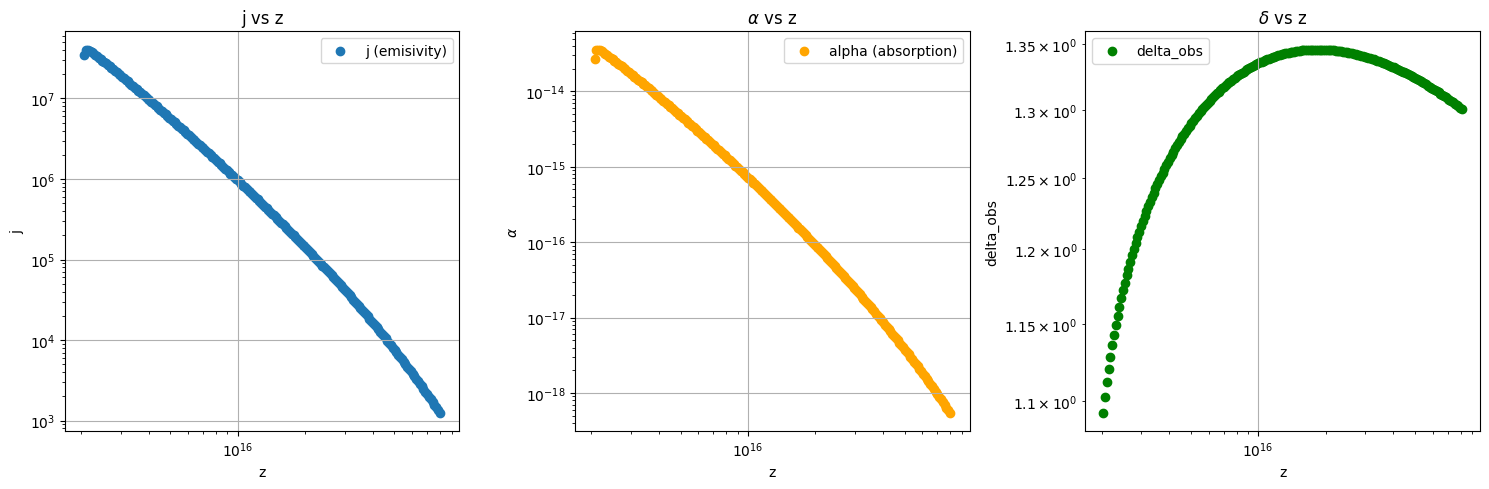

In [93]:
z, B, r_out, r_in, delta_obs = get_z_rz()
delta_obs = np.sqrt(delta_obs)
j, alpha = get_j_alpha(45.0, delta_obs)

plt.figure(figsize=(15, 5))
print(len(z))
# Plot j vs z
plt.subplot(1, 3, 1)
plt.scatter(z, j, label='j (emisivity)')
plt.xlabel('z')
plt.ylabel('j')
plt.xscale('log')
plt.yscale('log')
plt.title('j vs z')
plt.grid()
plt.legend()

# Plot alpha vs z
plt.subplot(1, 3, 2)
plt.scatter(z, alpha, label='alpha (absorption)', color='orange')
plt.xlabel('z')
plt.ylabel(r'$\alpha$')
plt.xscale('log')
plt.yscale('log')
plt.title(r'$\alpha$ vs z')
plt.grid()
plt.legend()

# Plot delta_obs vs z
plt.subplot(1, 3, 3)
plt.scatter(z, delta_obs, label='delta_obs', color='green')
plt.xlabel('z')
plt.ylabel('delta_obs')
plt.xscale('log')
plt.yscale('log')
plt.title(r'$\delta$ vs z')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

0.0


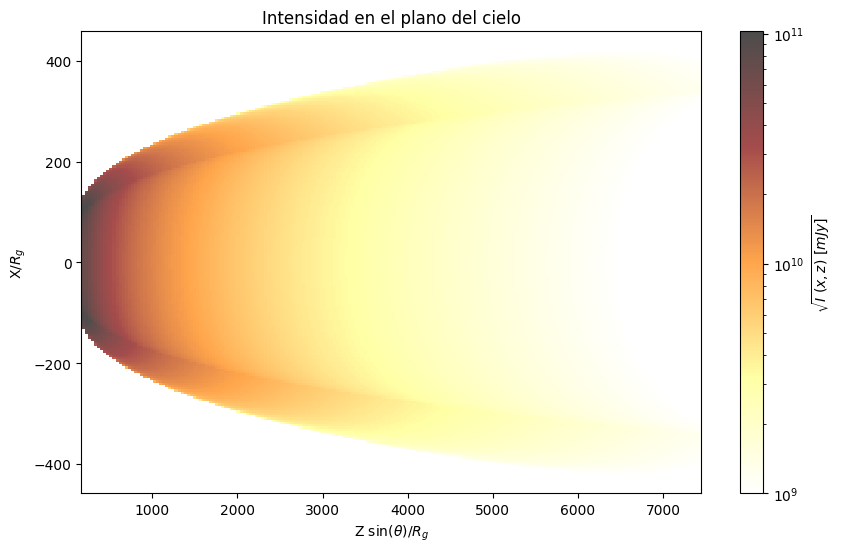

In [94]:
# Plotting
print(I.min())
palette = plt.cm.afmhot_r
plt.figure(figsize=(10, 6))
norm = matplotlib.colors.LogNorm(vmin=1e9, vmax=np.sqrt(I.max()*1e26))
plt.pcolormesh(Z_m * np.sin(incl)/R_g, X_m/R_g, np.sqrt(I*1e26), cmap=palette, norm=norm, alpha=0.7)
#plt.pcolormesh(Z_m * np.sin(incl)/R_g, -X_m/R_g, I, cmap=palette, norm=norm, alpha=0.7)
#plt.pcolormesh(Z_m * np.sin(incl) * convert, X_m * convert, I, cmap=palette, alpha=0.7)
plt.colorbar(label=r'$\sqrt{I~(x,z)~[mJy]}$')
plt.xlabel(r'Z $\sin(\theta)$/$R_g$')
plt.ylabel(r'X/$R_g$')
#plt.xlim(0,100000)
plt.title(r'Intensidad en el plano del cielo')
plt.show()

In [95]:
# Read the CSV file "EHT_OBS(RvZ)" and store its columns in two arrays
obs_data = pd.read_csv('./EHT_OBS(RvZ).csv')
obs_z = obs_data.iloc[:, 0].to_numpy()
obs_r = obs_data.iloc[:, 1].to_numpy()

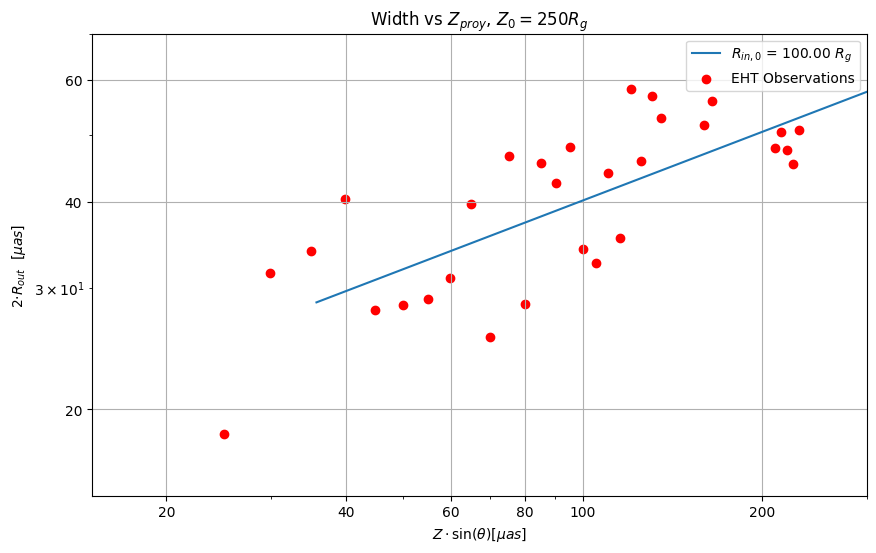

In [96]:
plt.figure(figsize=(10, 6))
# Plot the data
plt.plot(z*convert*1e3, 2*r_in*convert*1e3, label=fr'$R_{{in,0}}$ = {r_in.min()/R_g:.2f} $R_g$')
plt.scatter(obs_z, obs_r, label='EHT Observations', color='red')

# Set logarithmic scale
plt.xscale('log')
plt.yscale('log')
plt.xlim(15, 300)
plt.ylim(15, 70)
plt.xticks([20,40,60,80,100,200], [20,40,60,80,100,200])
plt.yticks([20,40,60], [20,40,60])
plt.title(r'Width vs $Z_{proy}$, $Z_0=250R_g$')
# Add labels, title, and legend
plt.ylabel(r'2$\cdot R_{out}$  $[\mu as]$')
plt.xlabel(r'$Z \cdot \sin ( \theta) [\mu as]$')
plt.legend()
plt.grid()
plt.show()

In [97]:
def Convolve_map( x_map, y_map, F_map, sigma_x, sigma_y ):    
    # The number of points in the convolved map depends on the beam size and the size of the original map.

    print(len(x_map),x_map.min(),x_map.max())
    # Extremes of the convolved map
    #Modificar esto
    y_min_c = y_map[0] - 5. * sigma_y # 5 beams to the left of the jet base
    y_max_c = y_map[-1] + 5. * sigma_y # 5 beams to the right of the jet end point
    x_min_c = x_map[0] - 4. * sigma_x # 3 beams above the jet lateral end point
    x_max_c = x_map[-1] + 4. * sigma_x # 3 beams below the jet lateral end point
    # Size of the convolved map
    ancho_x = x_max_c - x_min_c
    ancho_y = y_max_c - y_min_c 
    
    print(F_map.max())
    print(ancho_x, ancho_y)
    # Size of each cell of the convolved map
    Dx_c = f_Ny*sigma_x
    Dy_c = f_Ny*sigma_y

    Dx_c_rad = np.deg2rad(Dx_c * 1e-3 / 3600)
    Dy_c_rad = np.deg2rad(Dy_c * 1e-3 / 3600)

    F_map *= Dx_c_rad*Dy_c_rad
    # Number of cells of the convolved map
    Nx_c = int(ancho_x/Dx_c)
    Ny_c = int(ancho_y/Dy_c)
    print('Numero de celdas del mapa convolucionado:')
    print(Nx_c, Ny_c)

    # Position of the cells of the convolved map
    print(y_min_c)
    x_c = np.linspace( x_min_c, x_max_c, Nx_c)
    y_c = np.linspace( y_min_c, y_max_c, Ny_c)

    print('Dimension of the convolution grid: ' + str(Nx_c) + 'x' + str(Ny_c))
    
    F_map_c = np.ones((Nx_c, Ny_c))

    w_x = 0.5/sigma_x**2 # weight for x distance
    w_y = 0.5/sigma_y**2 # weight for y distance

    x_double = np.ones_like(F_map)
    y_double = np.ones_like(F_map)
    for j in range(len(y_map)):
        x_double[:, j] = x_map
    for i in range(len(x_map)):
        y_double[i, :] = y_map

    for i in range(Nx_c):
        for j in range(Ny_c):
            # Gaussian: (1/(2pi*sigma_x*sigma_y)) * exp(-((x-x_c)²/2.sigma_x² + (y-y_c)²/2.sigma_y²))
            gaussian = np.exp(-(np.square(x_double-x_c[i])*w_x + np.square(y_double-y_c[j])*w_y))
            F_map_c[i, j] = np.sum(F_map*gaussian)
            
    S_pre = np.sum(F_map)
    print('Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')
    # Gaussian beam -> exp(...)/(sigma*sqrt(2*pi)), both in x and y
    A_beam = 2 * np.pi * sigma_x * sigma_y     # = Gaussian normalization factor 
    A_cell = Dx_c * Dy_c              # cell sample size
    mJy_beam = A_cell/A_beam          # Transform mJy/beam -> mJy (for checks)
    S_post = np.sum(F_map_c) * mJy_beam
    print('Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
    print('post/pre = ' + str(S_post/S_pre) )
    
    return x_c, y_c, F_map_c

In [98]:
FWHM_x, FWHM_y= 0.0168, 0.0259 #FWHM in mas
sigma_x, sigma_y =FWHM_x/(2*np.sqrt(2*np.log(2))), FWHM_y/(2*np.sqrt(2*np.log(2))) 
X_c, Y_c, I_c = Convolve_map(X_m[0]*convert, Z_m.T[0]*np.sin(incl)*convert, I.T*1e26, sigma_x, sigma_y)

200 -0.06517170291148543 0.06517170291148543
1.0459477428616712e+22
0.18741783080232574 1.1454239285829346
Numero de celdas del mapa convolucionado:
175 694
-0.028443926172607433
Dimension of the convolution grid: 175x694
Pre-conv: S(GHz) = 153.93155504473893 mJy
Post-conv: S(GHz) = 152.6543162339815 mJy
post/pre = 0.9917025537071575


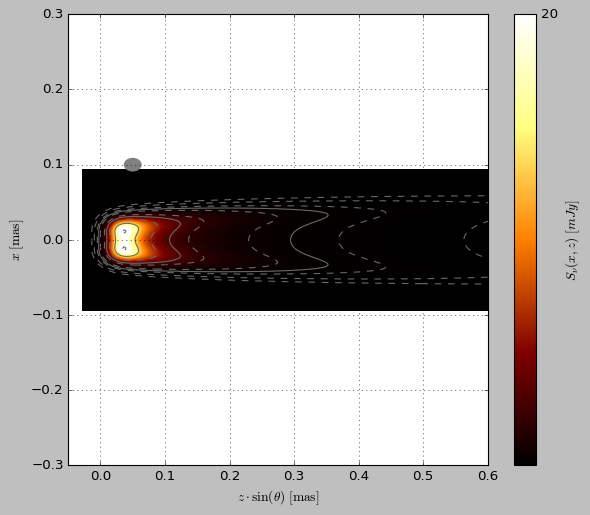

In [99]:
from matplotlib.patches import Ellipse
# nice_fonts = {
#         # Use LaTeX to write all text
#         "text.usetex": False,
#         "font.family": 'serif',
#         # Use 10pt font in plots, to match 10pt font in document
#         "axes.labelsize": 16,
#         "font.size": 16,
#         "axes.linewidth":1,
#         "axes.titlesize":20,
#         # Make the legend/label fonts a little smaller
#         "legend.fontsize": 10,
#         "xtick.labelsize": 14,
#         "ytick.labelsize": 14,
# }
# matplotlib.rcParams.update(nice_fonts)

#plt.clf()
with plt.style.context(('classic')):
    fig, ax = plt.subplots(1, 1, figsize=(7.8, 6.6)) # proportion: 2.6/2.2
    #fig, ax = plt.subplots(1, 1) 
    ax.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    ax.set_ylabel(r"$x~{\rm [mas]}$")
    ax.set_xlim([-0.05, .60])
    ax.set_ylim([-0.3, 0.3])
    palette = plt.cm.afmhot
    #cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
    ticks = [20,40,60,80,100]#[0.01, 0.05,  0.1,  0.15]
    norm = matplotlib.colors.Normalize(vmin=0, vmax=20)
    CS_conv = ax.contourf(Y_c, X_c, I_c, cmap=palette, norm=norm, levels=np.linspace(0,20, 500))
    # ticks = [0.001,0.01,0.1,1,10,100,1000,10000,1e5]#[0.01, 0.05,  0.1,  0.15]
    # norm = matplotlib.colors.LogNorm(vmin=5e-1, vmax=I_c.max())
    # CS_conv = ax.contourf(Y_c, X_c, I_c, cmap=palette, norm=norm, levels=np.geomspace(0.01,1e3, 500))

    # Add contours representing 1, 2, and 3 sigma levels
    sigma_levels = [3,2,1]
    obs_cont = [np.exp(-0.5 * (level**2)) * I_c.max() for level in sigma_levels]
    plot_cont = ax.contour(Y_c, X_c, I_c, linewidths=1, levels=obs_cont, extend="both", colors='dimgrey')

    obs_cont = np.geomspace(0.01, 1e3, 10)
    plot_cont = ax.contour(Y_c, X_c, I_c, linewidths=1, levels=obs_cont, extend="both", colors='dimgrey', linestyles='--')

    el = Ellipse((0.05,0.1), FWHM_y, FWHM_x, color='grey')
    ax.add_patch(el)

    ax.grid()
    plt.tight_layout()
    fig.colorbar( CS_conv, ticks=ticks ,label=r'$S_\nu(x,z)~[mJy]$')
    
    plt.savefig('Gaussian_Convolved_Map(1).png', dpi=300)

In [100]:
T_brillo=brightness_temperature(I_c, 230.0)
T_b=T_brillo
import os

filename = "T_brillo_output.txt"
mode = "a" if os.path.exists(filename) else "w"

with open(filename, mode) as f:
    if mode == "a":
        f.write("\n")
    np.savetxt(f, T_brillo)




1) Base
2) Lj=4d42 (1/2)
3) Lj= 10d42 (5/4)
4) r_out=120Rg (-15Rg)
5) a_inj= -0.4 (dsd -0.01), r_out=120Rg (-15Rg)
6) a_inj= 0.4 (dsd -0.01), r_out=120Rg (-15Rg)
7) r_out=105Rg (-30Rg)
8) r_out=120Rg, a_inj= -0.8, Lj=6d42
9) r_out=120Rg, a_inj= -0.8, Lj=8d42
10) r_out=120Rg, a_inj= -0.8, Lj=15d42
11) r_out=120Rg, a_inj= -0.6, Lj=10d42
12) r_out=100Rg, a_inj= -0.6, Lj=10d42
13) r_out=115Rg, a_inj= -0.4, Lj=10d42
14) r_out=135Rg, a_inj= 0.5, Lj=6d42, z0=220Rg
15) r_out=135Rg, a_inj= 0.5, Lj=6d42, z0=250Rg
16) r_out=135Rg, a_inj= 0.5, Lj=5d42, z0=250Rg
17) r_out=135Rg, a_inj= 0.5, Lj=5d42, z0=250Rg (r_in=100Rg)

1) r_out=135Rg, a_inj= 0.5, Lj=5d42, z0=250Rg (r_in=100Rg)
2) r_out=135Rg, a_inj= 0.5, Lj=6d42, z0=250Rg (r_in=100Rg)
3) r_out=135Rg, a_inj= 0.5, Lj=4d42, z0=250Rg (r_in=100Rg)
4) r_out=135Rg, a_inj= 0.4, Lj=5d42, z0=250Rg (r_in=100Rg)
5) r_out=135Rg, a_inj= 0.6, Lj=5d42, z0=250Rg (r_in=100Rg)

In [101]:
import numpy as np

def read_T_brillo_arrays(filename="T_brillo_output.txt"):
    arrays = []
    with open(filename, "r") as f:
        content = f.read()
        blocks = [block for block in content.strip().split('\n\n') if block.strip()]
        for block in blocks:
            arr = np.loadtxt(block.splitlines())
            arrays.append(arr)
    return arrays

T_brillo_arrays = read_T_brillo_arrays("T_brillo_output.txt")
print(len(T_brillo_arrays))

5


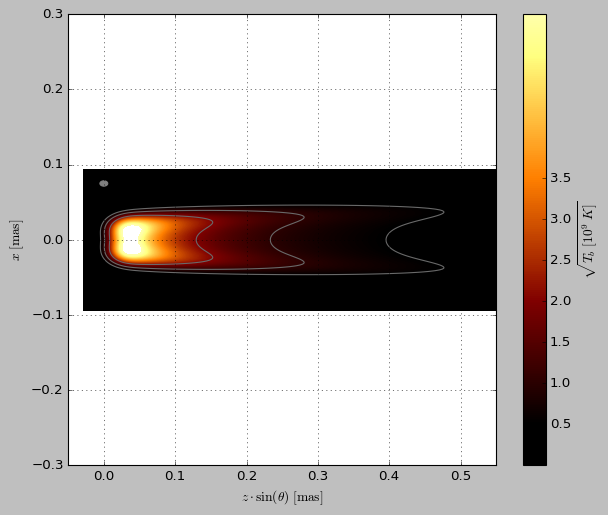

In [ ]:
with plt.style.context(('classic')):
    fig, ax = plt.subplots(1, 1, figsize=(7.8, 6.6)) # proportion: 2.6/2.2
    #fig, ax = plt.subplots(1, 1) 
    ax.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    ax.set_ylabel(r"$x~{\rm [mas]}$")
    ax.set_xlim([-0.05, 0.55])
    ax.set_ylim([-0.3, 0.3])
    palette = plt.cm.afmhot
    #cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
    ticks = [0.5,1.5,2.5,3.5, 4.5]  # Adjusted ticks for sqrt(T_b) in Gigakelvin
    norm = matplotlib.colors.Normalize(vmin=0.5, vmax=6.5)
    CS_conv = ax.contourf(Y_c, X_c, np.sqrt(T_b/1e9), cmap=palette, norm=norm, levels=np.linspace(0,5.5 , 700))

    #Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1 --> son 19? aprox
    obs_cont = np.array([-1,-0.5,0,0.5,1,2])
    plot_cont = ax.contour(Y_c, X_c, np.sqrt(T_b/1e9), linewidths=1, levels=obs_cont, extend="both", colors=['dimgrey'])

    el = Ellipse((0.0, 0.075), sigma_y, sigma_x, color='grey')
    ax.add_patch(el)

    ax.grid()
    plt.tight_layout()
    fig.colorbar( CS_conv, ticks=ticks ,label=r'$\sqrt{T_b~[10^9~K]}$')
    
    plt.savefig('./plots/SQRT_T_brightness_(230GHz).png', dpi=300)

In [102]:
obs_data = pd.read_csv('./EHT_OBS(TBvZ).csv')
obs_z = obs_data.iloc[:, 0].to_numpy()
obs_TB = obs_data.iloc[:, 1].to_numpy()
obs_data2 = pd.read_csv('./EHT_OBS(TBvZ)2.csv')
obs_z2 = obs_data2.iloc[:, 0].to_numpy()
obs_TB2 = obs_data2.iloc[:, 1].to_numpy()

/tmp/ipykernel_3947/482306299.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(tick_labels)


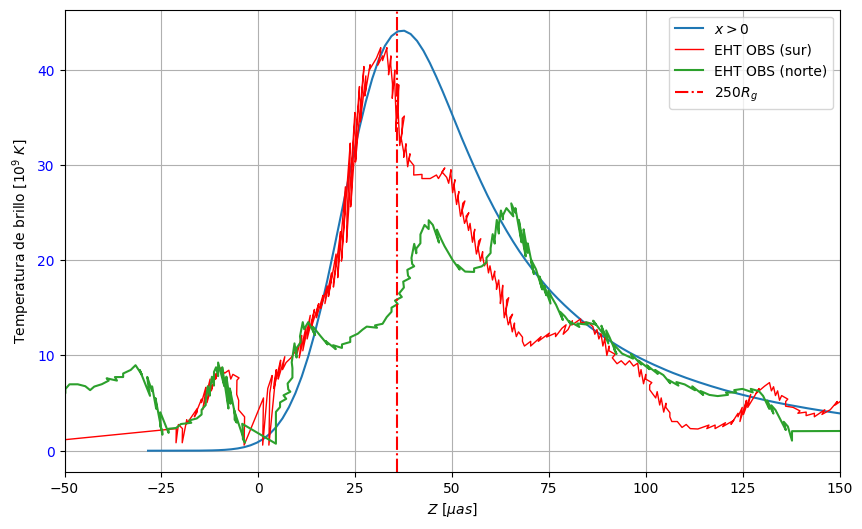

In [103]:
# Take the highest value along the X_c axis for each Y_c (i.e., max over rows)
T_b_df = pd.DataFrame(T_b/1e9, index=X_c, columns=Y_c)
T_b_df_plus=T_b_df[T_b_df.index > 0] #Promedio con valores de x positivos
T_b_df_minus=T_b_df[T_b_df.index < 0] #Promedio con valores de x positivos
# T_b_mean_values = T_b_df_plus.mean(axis=0)
# T_b_mean_values_minus = T_b_df_minus.mean(axis=0)
T_b_mean_values = T_b_df_plus.max(axis=0)
T_b_mean_values_minus = T_b_df_minus.max(axis=0)

plt.figure(figsize=(10, 6))
plt.plot(Y_c*1e3, T_b_mean_values, label='$x>0$')
#plt.plot(Y_c*1e3, -T_b_mean_values_minus, label='$x<0$')
plt.plot(obs_z, obs_TB, color='red', label='EHT OBS (sur)', lw=1)
plt.plot(obs_z2, -obs_TB2, color='C2', label='EHT OBS (norte)')
plt.axvline(x=250*R_g*convert*1e3, color='red', linestyle='-.', label='$250R_g$')
plt.xlabel(fr'$Z~[\mu as]$')
plt.ylabel(r'Temperatura de brillo $[10^9~K]$')
plt.xlim(-50, 150)
plt.legend()
plt.grid()

# Set y-ticks to absolute values and color positive as blue, negative as orange
ax = plt.gca()
y_ticks = ax.get_yticks()
tick_labels = []
tick_colors = []
for y in y_ticks:
    tick_labels.append(f"{abs(y):.0f}")
    if y >= 0:
        tick_colors.append('blue')
    else:
        tick_colors.append('orange')
ax.set_yticklabels(tick_labels)
for tick_label, color in zip(ax.get_yticklabels(), tick_colors):
    tick_label.set_color(color)

id=input('')
plt.savefig(fr'./plots/T_b_vs_Z_({id}).png', dpi=300)
plt.show()


In [104]:
import numpy as np

def read_T_brillo_arrays(filename="T_brillo_output.txt"):
    arrays = []
    with open(filename, "r") as f:
        content = f.read()
        blocks = [block for block in content.strip().split('\n\n') if block.strip()]
        for block in blocks:
            arr = np.loadtxt(block.splitlines())
            arrays.append(arr)
    return arrays

T_brillo_arrays = read_T_brillo_arrays("./T_brillo_output.txt")
print(len(T_brillo_arrays))

5


In [106]:
# T_brillo_1, T_brillo_2, T_brillo_3, T_brillo_4, T_brillo_5, T_brillo_6, T_brillo_7, T_brillo_8, T_brillo_9, T_brillo_10, T_brillo_11, T_brillo_12, T_brillo_13 = T_brillo_arrays[:]
T_brillo_1, T_brillo_2, T_brillo_3, T_brillo_4, T_brillo_5 = T_brillo_arrays[:]



In [107]:
for i in range(len(T_brillo_arrays)):
    print(len(T_brillo_arrays[i][0]))

694
694
694
694
694


In [108]:
obs_data = pd.read_csv('./EHT_OBS(TBvZ).csv')
obs_z = obs_data.iloc[:, 0].to_numpy()
obs_TB = obs_data.iloc[:, 1].to_numpy()

1) Base
2) Lj=4d42 (1/2)
3) a_inj= 10d42 (5/4)
4) r_out=120Rg (-15Rg)
5) a_inj= -0.4 (dsd -0.01), r_out=120Rg (-15Rg)
6) a_inj= 0.4 (dsd -0.01), r_out=120Rg (-15Rg)
7) r_out=105Rg (-30Rg)
8) r_out=120Rg, a_inj= -0.8, Lj=6d42
9) r_out=120Rg, a_inj= -0.8, Lj=8d42
10) r_out=120Rg, a_inj= -0.8, Lj=15d42
11) r_out=120Rg, a_inj= -0.6, Lj=10d42
12) r_out=100Rg, a_inj= -0.6, Lj=10d42
13) r_out=115Rg, a_inj= -0.4, Lj=10d42

/tmp/ipykernel_3947/1160834978.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(tick_labels)


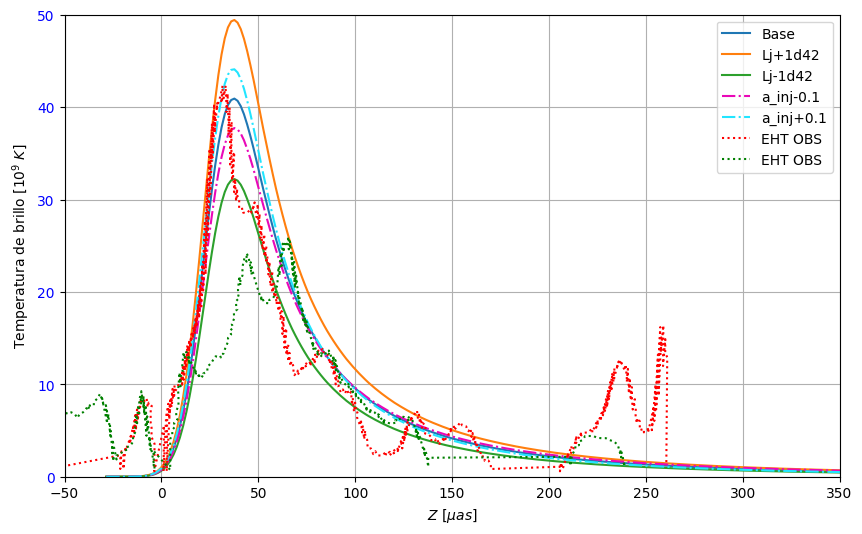

In [ ]:
# Take the highest value along the X_c axis for each Y_c (i.e., max over rows) using for loops
T_b_max_values_list = []
labels = [
    "Base",
    "Lj+1d42",
    "Lj-1d42",
    "a_inj-0.1",
    "a_inj+0.1"
]
colorlist =  [
    '#1f77b4', '#ff7f0e', '#2ca02c', "#e908b8", "#22e5ff",
    '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf',
    '#aec7e8', '#ffbb78', '#98df8a'
]
#T_brillo_list = [T_brillo_1, T_brillo_2, T_brillo_3, T_brillo_4, T_brillo_5, T_brillo_6, T_brillo_7, T_brillo_8, T_brillo_9, T_brillo_10, T_brillo_11, T_brillo_12, T_brillo_13]
# labels = [labels[0],labels[3], labels[4], labels[5]]
linestyles = ['-','-', '-', '-.','-.']
# colorlist = [colorlist[0],colorlist[3], colorlist[4], colorlist[5]]
T_brillo_list = [T_brillo_1, T_brillo_2, T_brillo_3,T_brillo_4, T_brillo_5]

plt.figure(figsize=(10, 6))
for i, T_brillo in enumerate(T_brillo_list):
    T_b_df = pd.DataFrame(T_brillo/1e9, columns=Y_c)
    # Use index > len/2 for x > 0 (positive x)
    T_b_df_plus = T_b_df[T_b_df.index > len(T_b_df)/2]
    # Max along x for each Y_c
    T_b_max_values = T_b_df_plus.max(axis=0)
    T_b_max_values_list.append(T_b_max_values)
    plt.plot(Y_c*1e3, T_b_max_values, color=colorlist[i], linestyle=linestyles[i], label=labels[i])

plt.plot(obs_z, obs_TB, color='red',linestyle=':', label='EHT OBS (south)')
plt.plot(obs_z2, -obs_TB2, color='green',linestyle=':', label='EHT OBS (north)')
#plt.plot(Y_c*1e3, -T_b_mean_values_minus, label='$x<0$')
plt.xlabel(fr'$Z~[\mu as]$')
plt.ylabel(r'Temperatura de brillo $[10^9~K]$')
plt.xlim(-50, 350)
plt.ylim(0,50)
plt.legend()
plt.grid()

# Set y-ticks to absolute values and color positive as blue, negative as orange
ax = plt.gca()
y_ticks = ax.get_yticks()
tick_labels = []
tick_colors = []
for y in y_ticks:
    tick_labels.append(f"{abs(y):.0f}")
    if y >= 0:
        tick_colors.append('blue')
    else:
        tick_colors.append('orange')
ax.set_yticklabels(tick_labels)
for tick_label, color in zip(ax.get_yticklabels(), tick_colors):
    tick_label.set_color(color)


plt.savefig('./plots/T_b_vs_Z_(max).png', dpi=300)
plt.show()

In [ ]:
T_b_df = pd.DataFrame(T_b, index=X_c, columns=Y_c)
T_b_df.index.name = 'X_c'
T_b_df.columns.name = 'Y_c'

In [ ]:
# Calculate the average over each column
T_b_xplus=T_b_df[T_b_df.index > 0] #Promedio con valores de x positivos
T_b_xminus=T_b_df[T_b_df.index < 0] #Promedio con valores de x negativos

In [ ]:
z, _, _, r_in, _ = get_z_rz()
Inner_Radius_z=interp1d(safe_log(z), safe_log(r_in), bounds_error=False, fill_value='extrapolate')
T_b_abs_columns = abs(Y_c)
r_in_values = np.exp(Inner_Radius_z(safe_log(T_b_abs_columns/convert/np.sin(incl))))
r_in_values *=convert
Bright_Temp = np.zeros(len(Y_c))
for i, value in enumerate(r_in_values):
    closest_index = T_b_xplus.index.get_indexer([value], method='nearest')[0]
    Bright_Temp[i]=T_b_xplus.iloc[closest_index, T_b_xplus.columns.get_loc(Y_c[i])]

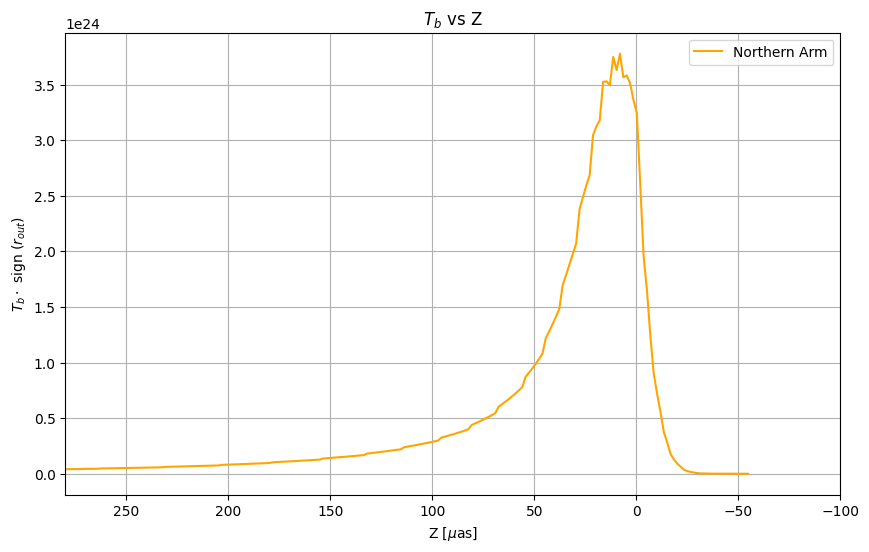

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(Y_c*1e3, Bright_Temp/1e9, label='Northern Arm', color='orange')
#plt.plot(Y_c*1e3, -T_b_df.loc['Average_-'], label='Southern Arm', color='blue')
plt.gca().invert_xaxis()
plt.xlim(280,-100)
plt.xlabel(r'Z [$\mu$as]')
plt.ylabel(r'$T_b \cdot$ sign $(r_{out})$')
plt.title(r'$T_b$ vs Z')
plt.legend()
plt.grid()
plt.show()

Que la temperatura de brillo de entre 24 y 40 en el maximo y despues decaiga

Al hacer este grafico algunas cosas se deberian mantener, quiza el centro no sea tan oscuro usando la misma escala de ellos y habria que ajustar la escala del anillo

Ademas, empezar a escribir notas tranqui de todo lo que es el calculo radiativo (algunas de las cosas que fuimos viendo al escribir sobre el pdf de notas) y poner algunos graficos de esos que habia hecho de la funcion l(x) y despues la funcion que modula al brillo (1-e^-l bla bla) lo de la convolucion (oh no, tengo que poner lo que aprendi :<>) y ese test de las fuentes puntuales


## Pruebas de convolucion

In [ ]:
z, _, r_out, _, _ = get_z_rz()
z = np.linspace(z.min(), z.max(), 200)
x = np.linspace(-r_out.max(), r_out.max(), 200)
I_puntual = np.zeros((len(z), len(x)))

In [ ]:
# I_puntual[100,100]=2e-3
I_puntual[88,100]=1
I_puntual[113,100]=1
FWHM=0.1
sigma_x=FWHM/(2*np.sqrt(2*np.log(2)))
sigma_y=FWHM/(2*np.sqrt(2*np.log(2)))
# sigma_x=1/(2*np.sqrt(2*np.log(2)))
# sigma_y=1/(2*np.sqrt(2*np.log(2)))
X_c, Y_c, I_puntual_c = Convolve_map(X_m[0]*convert, Z_m.T[0]*np.sin(incl)*convert, I_puntual.T, sigma_x, sigma_y)

200 -0.07389718781422953 0.07389718781422953
1.0
0.4875230957436667 1.4813373839064543
Numero de celdas del mapa convolucionado:
76 232
-0.20702051799279644
Dimension of the convolution grid: 76x232


KeyboardInterrupt: 

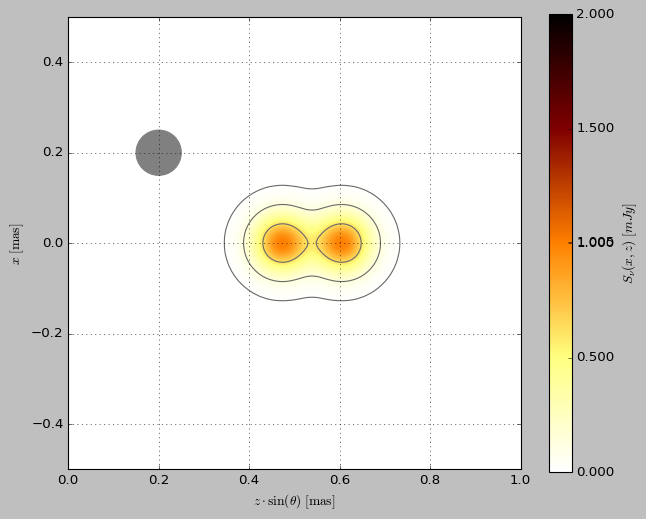

In [ ]:
from matplotlib.patches import Ellipse
with plt.style.context(('classic')):
    
    fig, ax = plt.subplots(1, 1, figsize=(7.8, 6.6)) # proportion: 2.6/2.2
    ax.set_aspect('equal', adjustable='box')
    #fig, ax = plt.subplots(1, 1) 
    ax.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    ax.set_ylabel(r"$x~{\rm [mas]}$")
    ax.set_xlim([-0.0,1])
    ax.set_ylim([-0.5, 0.5])
    palette = plt.cm.afmhot_r
    #cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
    ticks = [0, 0.5,1,I_puntual_c.max(),1.5,2]#[0.01, 0.05,  0.1,  0.15]
    norm = matplotlib.colors.Normalize(vmin=0, vmax=2)
    CS_conv = ax.contourf(Y_c, X_c, I_puntual_c, cmap=palette, norm=norm, levels=np.linspace(0,2, 500))
    # # ticks = [0.001,0.01,0.1,1,10,100,1000,10000,1e5]#[0.01, 0.05,  0.1,  0.15]
    # norm = matplotlib.colors.LogNorm(vmin=1e-3, vmax=I_puntual_c.max())
    # CS_conv = ax.contourf(Y_c, X_c, I_puntual_c, cmap=palette, norm=norm, levels=np.geomspace(1e-3,5 e4, 500))

    #Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1 --> son 19? aprox
    # # obs_cont = np.linspace(0.01,1.1,10)
    obs_cont = [0.0111*I_puntual_c.max(), 0.1353*I_puntual_c.max(), 0.6065*I_puntual_c.max()]
    plot_cont = ax.contour(Y_c, X_c, (I_puntual_c), linewidths=1, levels=obs_cont, extend="both", colors='dimgrey')

    el = Ellipse((0.2,0.2), FWHM, FWHM, color='grey')
    ax.add_patch(el)

    ax.grid()
    plt.tight_layout()
    fig.colorbar( CS_conv, ticks=ticks ,label=r'$S_\nu(x,z)~[mJy]$')
    plt.savefig(fr'Gaussian_Convolved_Map.png', dpi=300)

In [ ]:
T_brillo=brightness_temperature(I_puntual_c, 230.0)

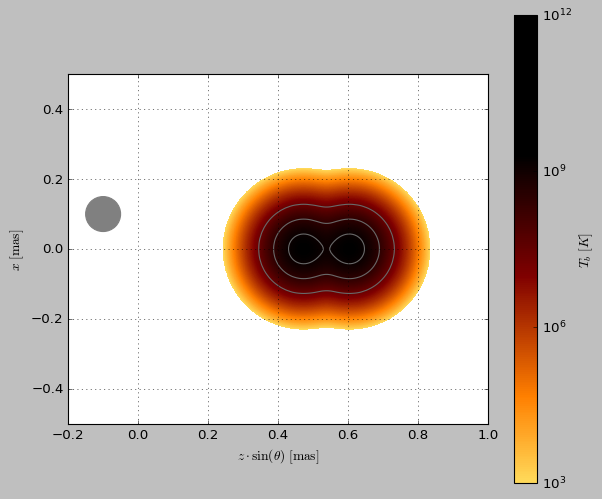

In [ ]:
with plt.style.context(('classic')):
    fig, ax = plt.subplots(1, 1, figsize=(7.8, 6.6)) # proportion: 2.6/2.2
    ax.set_aspect('equal', adjustable='box')
    #fig, ax = plt.subplots(1, 1) 
    ax.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    ax.set_ylabel(r"$x~{\rm [mas]}$")
    ax.set_xlim([-0.2, 1])
    ax.set_ylim([-0.5, 0.5])
    palette = plt.cm.afmhot_r
    #cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
    # ticks = [0.1, 0.5, 0.9,1.1]#[0.01, 0.05,  0.1,  0.15]
    # norm = matplotlib.colors.Normalize(vmin=0, vmax=I_c.max()/1e2)
    # CS_conv = ax.contourf(Y_c, X_c, I_c/1e2, cmap=palette, norm=norm, levels=np.linspace(0,1.1, 500))
    ticks = [1e3,1e6,1e9,1e12,1e15]#[0.01, 0.05,  0.1,  0.15]
    norm = matplotlib.colors.LogNorm(vmin=1e0, vmax=T_brillo.max())
    CS_conv = ax.contourf(Y_c, X_c, T_brillo, cmap=palette, norm=norm, levels=np.geomspace(1e3,1e12, 500))

    #Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1 --> son 19? aprox
    # # obs_cont = np.linspace(0.01,1.1,10)
    # obs_cont = np.geomspace(0.01,1e2,10)
    # plot_cont = ax.contour(Y_c, X_c, (I_c), linewidths=1, levels=obs_cont, extend="both", colors='dimgrey')

    obs_cont = [0.0111*T_brillo.max(), 0.1353*T_brillo.max(), 0.6065*T_brillo.max()]
    plot_cont = ax.contour(Y_c, X_c, (T_brillo), linewidths=1, levels=obs_cont, extend="both", colors='dimgrey')

    el = Ellipse((-FWHM,FWHM), FWHM, FWHM, color='grey')
    ax.add_patch(el)


    ax.grid()
    plt.tight_layout()
    fig.colorbar( CS_conv, ticks=ticks ,label=r'$T_b~[K]$')

## -------------------------------------------------------------------------